## step 0

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import streamflow_model as S

# load the released (bugged) model and build standardized inputs + target (try.ipynb cell 1)
weights = S.load_weights("model/streamflow_model_bug.npz")
feats = S.build_features("data/train.csv", "model/feature_scaler.json")
X, truth = feats["X"], feats["truth"]
print(f"{len(X)} usable examples, {X.shape[1]} features each")

18685 usable examples, 77 features each


In [25]:
# run the model, and grab hidden activations (try.ipynb cell 9)
pred, acts = S.forward(weights, X, return_hidden=True) #acts: activation; pred: predicted streamflow
print("layers with activations:", list(acts.keys()))
dates = feats["datetime"]   # lines up with X row for row
rain = feats["rain"]        # hourly rainfall, mm


layers with activations: ['fc1', 'fc2', 'fc3', 'fc4', 'fc5', 'fc6']


In [26]:
#get fct 5's activations, and fct 6's weights
fc6_weights = weights["fc6.weight"]
print(fc6_weights.shape)
fc5_acts = acts["fc5"]
print(fc5_acts.shape)



(56, 56)
(18685, 56)


In [27]:
#make a dataframe to store stuff, inhereted from plot.ipynb
plot_df = pd.DataFrame({"pred": pred.astype(np.float64), "truth": truth.astype(np.float64), "rain": rain.astype(np.float64)}, index=pd.DatetimeIndex(dates)) 

In [28]:
#diff -- positive control of having phantom water case
plot_df["diff"] = plot_df["pred"] - plot_df["truth"]
plot_df["diff"].sum() #yes it is wround 60.2 mm match with Sam's per hour average bias

np.float64(60.01548702233413)

In [29]:
#get the low flow portion, defined by less than median.
median_truth = plot_df["truth"].median()
plot_df["low"] = plot_df["truth"] < median_truth
low_sum = plot_df.loc[plot_df["low"], "diff"].sum()
high_sum = plot_df.loc[~plot_df["low"], "diff"].sum()

print(f"Low flow sum: {low_sum}, hours: {plot_df.loc[plot_df["low"], 'truth'].count()}")
print(f"High flow sum: {high_sum}, hours: {plot_df.loc[~plot_df["low"], 'truth'].count()}")

Low flow sum: 67.27281358894834, hours: 9342
High flow sum: -7.257326566614211, hours: 9343


In [30]:
#floor extraction: floor rule do atol=1e-6
min_pred = pred.min()
plot_df["floor"] = np.isclose(pred, min_pred, atol=1e-6)


check = pd.DataFrame({
    "hours":       plot_df["floor"].sum(),                  # a bool column's .sum() counts the Trues
    "share":       plot_df["floor"].mean(),                 # .mean() of bools = fraction True
    "sum_diff_mm": plot_df.loc[plot_df["floor"], "diff"].sum(),
}, index=["atol=1e-6 (default rtol)"])
check.round(4)


,hours,share,sum_diff_mm
atol=1e-6 (default rtol),4843,0.2592,9.5468


In [31]:
plot_df

,pred,truth,rain,diff,low,floor
2023-10-29 11:00:00,0.030302,0.025719,0.0,0.004583,False,False
2023-10-29 12:00:00,0.026052,0.025616,0.0,0.000436,False,False
2023-10-29 13:00:00,0.021917,0.025514,0.0,-0.003597,False,False
2023-10-29 14:00:00,0.019328,0.025412,0.0,-0.006084,False,False
2023-10-29 15:00:00,0.019153,0.025310,0.0,-0.006157,False,False
...,...,...,...,...,...,...
2025-12-16 14:00:00,0.007822,0.000410,0.0,0.007411,True,True
2025-12-16 15:00:00,0.007822,0.000409,0.0,0.007413,True,True
2025-12-16 16:00:00,0.007822,0.000407,0.0,0.007414,True,True
2025-12-16 17:00:00,0.007822,0.000405,0.0,0.007416,True,True


In [32]:
plot_df.groupby(["floor", "low"])["diff"].agg(["count", "sum", "mean"]) #groupby is a sorting
#match with the low flow sum number (of course......)

count        sum      mean
floor low                              
False False   8800   0.946241  0.000108
      True    5042  49.522451  0.009822
True  False    543  -8.203568 -0.015108
      True    4300  17.750363  0.004128

In [33]:
#get the Leak and Normal hour labels -- the floor & low flow stuff
# leak: not floor, low flow; normal: not floor, high flow
plot_df["leak"] = ~plot_df["floor"] & plot_df["low"]
plot_df["normal"] = ~plot_df["floor"] & ~plot_df["low"]
#double check whether it get the stuff correct.
print(plot_df.loc[plot_df["leak"], "diff"].sum())
print(plot_df.loc[plot_df["normal"]].shape)

49.52245060080895
(8800, 8)


In [34]:
# save plot_df so other notebooks can load it without re-running the model.
# the DatetimeIndex goes out as the first column; bool columns come back as bool on their own.
plot_df.to_csv("cache/plot_df.csv")

# round trip check: read it back the way another notebook would, compare to the original.
# float_precision="round_trip": read_csv's default float parser is off by ~1e-15 on some values, which makes .equals() False
back = pd.read_csv("cache/plot_df.csv", index_col=0, parse_dates=True, float_precision="round_trip")
print(back.dtypes.to_dict())
print("same values:", back.equals(plot_df))


{'pred': dtype('float64'), 'truth': dtype('float64'), 'rain': dtype('float64'), 'diff': dtype('float64'), 'low': dtype('bool'), 'floor': dtype('bool'), 'leak': dtype('bool'), 'normal': dtype('bool')}
same values: True


In [35]:
#from hemal's code:
def forward_from(w, layer, h):
    """Continue the forward pass from the activations of one hidden layer to the prediction.

    Runs the layers AFTER `layer`, then the output layer. Nothing before `layer` is touched,
    so `h` can be an edited version of the real activations (the steering tests in Step 3).

    Parameters
    ----------
    w : dict
        {name: array} weights and biases, as returned by S.load_weights, e.g. w["fc6.weight"] (56, 56),
        w["fc6.bias"] (56,), w["out.weight"] (1, 56), w["out.bias"] (1,).
    layer : str
        The hidden layer that PRODUCED `h`, one of "fc1" .. "fc6". The loop starts at the next layer.
        For fc5 activations pass "fc5": the function runs fc6 and the output layer.
    h : array, shape (n_hours, 56)
        Post-ReLU activations of `layer`, one row per hour. For the real activations use acts[layer];
        for a steering test pass the modified copy.

    Returns
    -------
    array, shape (n_hours,)
        Predicted streamflow in mm/hr, same order as the rows of `h`.

    Notes
    -----
    Per layer: h <- relu(h @ W.T + b), with W stored as (out, in), so W.T maps 56 inputs to 56 outputs.
    Output layer: y = h @ W_out.T + b_out gives shape (n_hours, 1); [:, 0] drops the trailing axis.
    Check: forward_from(weights, "fc5", acts["fc5"]) must match S.forward(weights, X) to ~1e-6.
    """
    for name in S.LAYERS[S.LAYERS.index(layer) + 1:]:
        h = S.relu(h @ w[f"{name}.weight"].T + w[f"{name}.bias"])
    return (h @ w["out.weight"].T + w["out.bias"])[:, 0]


## Step 1: whitening contrast

In [36]:
# calculate average of leak (L) and normal hour (N), and find distance
L = plot_df["leak"].values #these are just boolean values, are the masks
N = plot_df["normal"].values


#do on fc5 output, select what is leak and what is normal
u_L = fc5_acts[L].mean(axis=0) #should each output a (56,) vector
u_N = fc5_acts[N].mean(axis=0)

d = u_L - u_N

dead5= [2, 8, 11, 24, 28, 30, 35, 36, 38, 52, 55]

u_L[dead5] #these are exactly 0 for whatever hour did. So just act as a sanity check


array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], dtype=float32)

In [37]:
#calculate covariance matrix of Normal hour (N), prepare to do whitening contrast of N
Sigma_N = np.cov(fc5_acts[N], rowvar=False) #default ddof=1 matches the n_N - 1 rule

In [38]:
# solve for v_hat at several eps. Everything in float64 from here on:
# fc5_acts is float32 straight out of forward(); sums over 18,685 rows and a solve that
# divides by variances ~1e-5 both lose digits in float32, so cast once and reuse H.
H = fc5_acts.astype(np.float64)

mu_L = H[L].mean(axis=0)              # (56,)  mean activation of leak hours
mu_N = H[N].mean(axis=0)              # (56,)  mean activation of normal hours
d = mu_L - mu_N                       # (56,)  the plain gap
Sigma_N = np.cov(H[N], rowvar=False)  # (56, 56) covariance of normal hours, ddof=1

avg_diag = np.trace(Sigma_N) / 56     # mean variance per unit; eps is measured against this
fracs = [1e-4, 1e-3, 1e-2, 1e-1, 1.0]

v_hat = {}                            # frac -> unit-length v
for frac in fracs:
    eps = frac * avg_diag
    v = np.linalg.solve(Sigma_N + eps * np.eye(56), d)   # (Sigma_N + eps I) v = d
    v_hat[frac] = v / np.linalg.norm(v)

print(f"avg_diag = {avg_diag:.3e}, rank(Sigma_N) = {np.linalg.matrix_rank(Sigma_N)}, |d| = {np.linalg.norm(d):.4f}")
print("norm of v_hat on dead units, per frac:", {f: float(np.linalg.norm(v_hat[f][dead5])) for f in fracs})


avg_diag = 3.132e-04, rank(Sigma_N) = 33, |d| = 0.1153
norm of v_hat on dead units, per frac: {0.0001: 0.0, 0.001: 0.0, 0.01: 0.0, 0.1: 0.0, 1.0: 0.0}


In [39]:
# the checks table: one row per eps
d_hat = d / np.linalg.norm(d)

# PC1 of fc5 over the off-floor hours (L and N together). eigh sorts ascending, so PC1 is the last column.
evals, evecs = np.linalg.eigh(np.cov(H[~plot_df["floor"].values], rowvar=False))
pc1 = evecs[:, -1]

def separation(v):
    """gap between the L and N means of s = H @ v, in units of their pooled std."""
    s = H @ v
    return (s[L].mean() - s[N].mean()) / np.sqrt(0.5 * (s[L].var(ddof=1) + s[N].var(ddof=1)))

rows = []
for i, frac in enumerate(fracs):
    v = v_hat[frac]
    rows.append({
        "frac": frac,
        "eps": f"{frac * avg_diag:.1e}",
        "|cos(v,PC1)|": abs(v @ pc1),
        "|cos(v,d)|": abs(v @ d_hat),
        "separation": separation(v),
        "|cos(v,prev v)|": np.nan if i == 0 else abs(v @ v_hat[fracs[i - 1]]),
    })
e1_table = pd.DataFrame(rows).set_index("frac")
print(f"plain gap d for reference: |cos(d,PC1)| = {abs(d_hat @ pc1):.3f}, separation = {separation(d_hat):.3f}")
e1_table.round(4)


plain gap d for reference: |cos(d,PC1)| = 0.990, separation = 1.185


,eps,"|cos(v,PC1)|","|cos(v,d)|",separation,"|cos(v,prev v)|"
frac,,,,,
0.0001,3.1e-08,0.0091,0.0200,1.7120,NaN
0.0010,3.1e-07,0.0261,0.0566,1.6929,0.7720
0.0100,3.1e-06,0.0473,0.0987,1.6962,0.8366
0.1000,3.1e-05,0.0968,0.1819,1.6978,0.8762
1.0000,3.1e-04,0.2490,0.3783,1.6011,0.8100


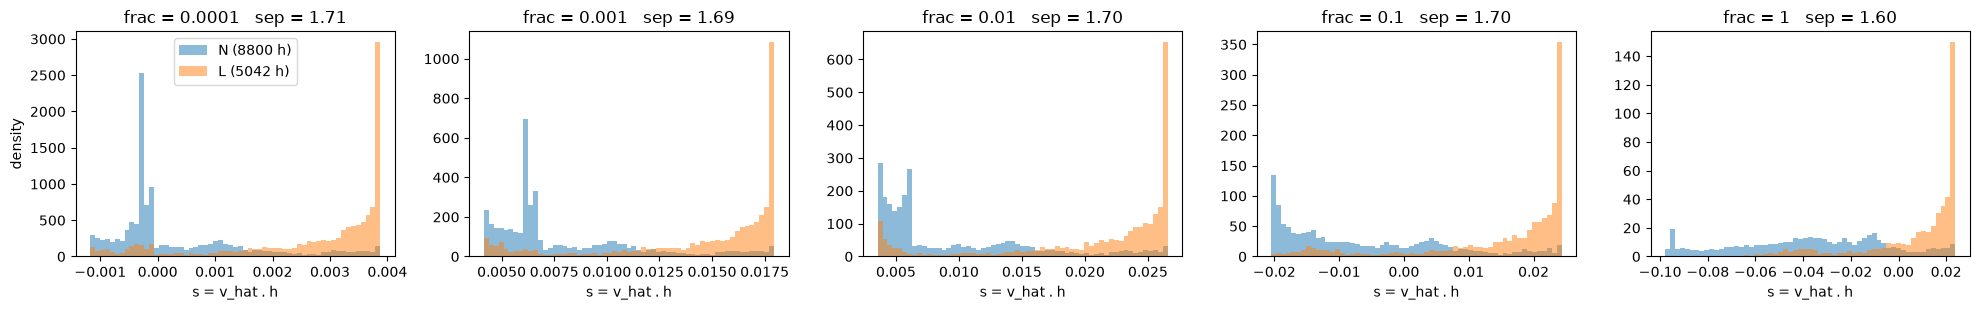

In [40]:
# the distribution of s = v_hat . h on L vs N, one panel per eps
fig, axes = plt.subplots(1, len(fracs), figsize=(4 * len(fracs), 3.2), sharey=False)   # x ranges differ by 100x across eps, so y cannot be shared
for ax, frac in zip(axes, fracs):
    s = H @ v_hat[frac]
    bins = np.linspace(min(s[L].min(), s[N].min()), max(s[L].max(), s[N].max()), 60)
    ax.hist(s[N], bins=bins, density=True, alpha=0.5, label=f"N ({N.sum()} h)")
    ax.hist(s[L], bins=bins, density=True, alpha=0.5, label=f"L ({L.sum()} h)")
    ax.set_title(f"frac = {frac:g}   sep = {separation(v_hat[frac]):.2f}")
    ax.set_xlabel("s = v_hat . h")
axes[0].set_ylabel("density"); axes[0].legend()
fig.tight_layout()
fig.savefig("figures/e1_score_hist.png", dpi=150)
plt.show()


## Step 2: |cos| table against the teammates' directions

In [41]:
# Step 2a: rebuild the teammates' two weight-only candidate directions from the team notebook (investigation_log)
# v_E (Stage 08, "E: weight-only"): read direction x of a rank-1 edit u x^T chosen so that fc6's rows and columns
#     return to the weight-decay balance rule. Needs the fc5 decoy block masked (repeated value 0.2 on dead columns).
# m   (Stage 09, "balance shrink"): shared direction of the nine oversized fc6 rows, from an SVD of just those rows
#     with the dead fc5 columns zeroed.
Wd = {k: v.astype(np.float64) for k, v in weights.items()}
M6 = Wd["fc6.weight"]

# decoy mask for fc5.weight: any value that appears more than twice (team notebook, "decoy = {}" cell)
vals, counts = np.unique(weights["fc5.weight"], return_counts=True)
decoy5 = np.isin(weights["fc5.weight"], vals[counts > 2])
W5nd = Wd["fc5.weight"].copy(); W5nd[decoy5] = 0.0

col_excess = (M6 ** 2).sum(axis=0) - ((W5nd ** 2).sum(axis=1) + Wd["fc5.bias"] ** 2)      # > 0: fc6 column too big
row_excess = ((M6 ** 2).sum(axis=1) + Wd["fc6.bias"] ** 2) - (Wd["out.weight"] ** 2).sum(axis=0)  # > 0: fc6 row too big
bad_rows = np.where(row_excess > 0.01)[0]
u = np.zeros(56); u[bad_rows] = np.sqrt(row_excess[bad_rows]); u /= np.linalg.norm(u)
cu = M6.T @ u; disc = cu ** 2 - col_excess
x = np.where(disc >= 0, cu - np.sign(cu) * np.sqrt(np.maximum(disc, 0)), cu)
x[col_excess <= 0] = 0.0
x[1] = 0.0                                   # the team left fc5 unit 1 out by hand (overshoots)
v_E = x / np.linalg.norm(x)

R6 = [4, 20, 30, 32, 35, 41, 43, 48, 50]     # the nine oversized fc6 rows (team notebook, "R6_sel")
W6m = M6.copy(); W6m[:, dead5] = 0.0
_, s_rows, V_rows = np.linalg.svd(W6m[R6])
m = V_rows[0] * np.sign(V_rows[0].sum())

top = lambda v, k=6: ", ".join(f"{i}:{v[i]:+.2f}" for i in np.argsort(-np.abs(v))[:k])
print("v_E top loadings:", top(v_E), "   (team notebook: 51:+0.60, 47:+0.52, 10:+0.29, 41:-0.28)")
print("m   top loadings:", top(m),   "   (team notebook: 1:-0.37, 51:+0.23, 40:+0.23, 6:+0.22)")
print(f"|cos(v_E, m)| = {abs(v_E @ m):.2f}   (team notebook: 0.63)")

# leak_direction.npy (Agent B's consensus direction) is not in the repo; load it if it has been dropped into cache/
leak_path = "cache/leak_direction.npy"
import os
if os.path.exists(leak_path):
    leak = np.load(leak_path).astype(np.float64); leak /= np.linalg.norm(leak)
    print("leak_direction.npy loaded, top loadings:", top(leak))
else:
    leak = None
    print(f"{leak_path} not found: leak_direction left out of the table")

v_E top loadings: 51:+0.60, 47:+0.52, 10:+0.29, 41:-0.28, 45:+0.23, 25:+0.17    (team notebook: 51:+0.60, 47:+0.52, 10:+0.29, 41:-0.28)
m   top loadings: 1:-0.37, 51:+0.23, 40:+0.23, 6:+0.22, 16:+0.22, 54:+0.22    (team notebook: 1:-0.37, 51:+0.23, 40:+0.23, 6:+0.22)
|cos(v_E, m)| = 0.63   (team notebook: 0.63)
cache/leak_direction.npy not found: leak_direction left out of the table


In [42]:
# Step 2b: |cos| table between every candidate direction (all unit length, fc5-activation space)
dirs = {f"E1 frac={f:g}": v_hat[f] for f in fracs}
dirs.update({"plain gap d": d_hat, "v_E (Stage 08)": v_E, "m (Stage 09)": m, "PC1 (off-floor)": pc1})
if leak is not None:
    dirs["leak_direction (B)"] = leak
names = list(dirs)
cos_table = pd.DataFrame([[abs(dirs[a] @ dirs[b]) for b in names] for a in names], index=names, columns=names)
cos_table.to_csv("cache/step2_cos_table.csv")
np.savez("cache/e1_vhat.npz", **{f"frac_{f:g}": v_hat[f] for f in fracs})   # the E1 family, (56,) each
cos_table.round(2)

,E1 frac=0.0001,E1 frac=0.001,E1 frac=0.01,E1 frac=0.1,E1 frac=1,plain gap d,v_E (Stage 08),m (Stage 09),PC1 (off-floor)
E1 frac=0.0001,1.00,0.77,0.39,0.23,0.13,0.02,0.03,0.03,0.01
E1 frac=0.001,0.77,1.00,0.84,0.60,0.35,0.06,0.04,0.09,0.03
E1 frac=0.01,0.39,0.84,1.00,0.88,0.57,0.10,0.05,0.13,0.05
E1 frac=0.1,0.23,0.60,0.88,1.00,0.81,0.18,0.08,0.12,0.10
E1 frac=1,0.13,0.35,0.57,0.81,1.00,0.38,0.09,0.12,0.25
plain gap d,0.02,0.06,0.10,0.18,0.38,1.00,0.29,0.78,0.99
v_E (Stage 08),0.03,0.04,0.05,0.08,0.09,0.29,1.00,0.63,0.30
m (Stage 09),0.03,0.09,0.13,0.12,0.12,0.78,0.63,1.00,0.81
PC1 (off-floor),0.01,0.03,0.05,0.10,0.25,0.99,0.30,0.81,1.00


## Step 3: causal tests (activation steering, then blinding fc6)

In [43]:
# Step 3 setup check: the unmodified fc5 activations pushed through fc6 and the output layer must give back pred
p_check = forward_from(weights, "fc5", fc5_acts)
print("max |forward_from - pred| with float32 activations:", np.abs(p_check - pred).max())
print("max |forward_from - pred| with float64 H:          ", np.abs(forward_from(weights, "fc5", H) - pred).max())

max |forward_from - pred| with float32 activations: 0.0
max |forward_from - pred| with float64 H:           4.582204982117588e-08


In [44]:
# Step 3: steering along each candidate direction v (unit length).
#   score of every hour        s = h . v
#   remove on L                h' = h - (s - m_N) v      (L hours moved to the N mean along v)
#   add on N                   h' = h + (m_L - m_N) v    (N hours moved to the L mean along v)
# then forward_from(weights, "fc5", h') and the floor x flow table of pred' - truth.
# Subtracting along v can push a post-ReLU activation below 0, which is a state fc5 can never produce,
# so the removal is also run with h' clipped at 0 ("clipped"), and the share of L hours touched is reported.
diff_before = pred.astype(np.float64) - truth
def steer(v, label):
    v = v / np.linalg.norm(v)
    s = H @ v
    m_L, m_N = s[L].mean(), s[N].mean()
    h_rm = H.copy();  h_rm[L] -= np.outer(s[L] - m_N, v)          # remove on L
    h_add = H.copy(); h_add[N] += (m_L - m_N) * v                 # add on N
    p_rm, p_rm_clip, p_add = (forward_from(weights, "fc5", h) for h in (h_rm, np.maximum(h_rm, 0), h_add))
    return {
        "direction": label,
        "L sum before": diff_before[L].sum(),
        "L after remove": (p_rm - truth)[L].sum(),
        "L after remove (clipped)": (p_rm_clip - truth)[L].sum(),
        "N after remove": (p_rm - truth)[N].sum(),
        "N sum before": diff_before[N].sum(),
        "N after add": (p_add - truth)[N].sum(),
        "NSE after remove": S.nse(p_rm_clip, truth),
        "L hours with h'<0": (h_rm[L] < 0).any(axis=1).mean(),
    }

rng = np.random.default_rng(0)
rand = rng.standard_normal(56); rand[dead5] = 0.0                 # control: a random live direction
steer_rows = [steer(v, k) for k, v in dirs.items()] + [steer(rand, "random (control)")]
steer_table = pd.DataFrame(steer_rows).set_index("direction")
steer_table.to_csv("cache/step3_steer_table.csv")
print(f"baseline NSE = {S.nse(pred, truth):.4f}; sums are mm over the {L.sum()} L hours / {N.sum()} N hours")
steer_table.round(3)

baseline NSE = 0.6793; sums are mm over the 5042 L hours / 8800 N hours


,L sum before,L after remove,L after remove (clipped),N after remove,N sum before,N after add,NSE after remove,L hours with h'<0
direction,,,,,,,,
E1 frac=0.0001,49.522,49.663,49.674,0.946,0.946,0.763,0.679,1.000
E1 frac=0.001,49.522,50.690,50.763,0.946,0.946,-0.553,0.679,1.000
E1 frac=0.01,49.522,52.547,52.576,0.946,0.946,-2.792,0.677,0.999
E1 frac=0.1,49.522,56.034,57.606,0.946,0.946,-6.430,0.673,0.999
E1 frac=1,49.522,65.964,74.899,0.946,0.946,-16.384,0.653,0.910
plain gap d,49.522,182.514,182.532,0.946,0.946,-203.271,0.337,0.118
v_E (Stage 08),49.522,75.916,75.949,0.946,0.946,-38.520,0.651,1.000
m (Stage 09),49.522,171.238,171.387,0.946,0.946,-164.980,0.386,1.000
PC1 (off-floor),49.522,185.231,185.309,0.946,0.946,-202.907,0.325,0.099


In [45]:
# Step 3, weight-side version of the same causal test: make fc6 blind to v.
#   W6' = W6 (I - v v^T)   removes the component of every fc6 input along v, for ALL hours at once.
# If v is the trigger read-direction, the L excess should fall towards the N level and NSE should hold.
# The team's two actual rank-1 repairs (u x^T edits, not projections) are listed for reference.
delta_E = np.outer(u, x)                                                   # Stage 08 edit (u, x from the Step 2a cell)
D57 = np.zeros((56, 56)); D57[R6] = (1 - 0.57) * np.outer(W6m[R6] @ m, m)  # Stage 09 shrink at c = 0.57
def blind_row(W6_new, label):
    w_test = dict(weights); w_test["fc6.weight"] = W6_new.astype(np.float32)
    p = S.forward(w_test, X); e = p - truth
    return {"edit": label, "edit size": np.linalg.norm(M6 - W6_new), "bias (mm/hr)": e.mean(),
            "L sum": e[L].sum(), "N sum": e[N].sum(), "floor sum": e[plot_df["floor"].values].sum(),
            "NSE": S.nse(p, truth)}
blind_rows = [blind_row(M6, "none (bugged model)")]
blind_rows += [blind_row(M6 - np.outer(M6 @ (v / np.linalg.norm(v)), v / np.linalg.norm(v)), f"blind to {k}") for k, v in dirs.items()]
blind_rows += [blind_row(M6 - delta_E, "team Stage 08 edit u x^T"), blind_row(M6 - D57, "team Stage 09 shrink c=0.57")]
blind_table = pd.DataFrame(blind_rows).set_index("edit")
blind_table.to_csv("cache/step3_blind_table.csv")
blind_table.round(4)

,edit size,bias (mm/hr),L sum,N sum,floor sum,NSE
edit,,,,,,
none (bugged model),0.0000,0.0032,49.522400,0.946200,9.546800,0.6793
blind to E1 frac=0.0001,0.0291,0.0032,49.682800,0.995500,9.741100,0.6792
blind to E1 frac=0.001,0.0822,0.0036,52.049400,2.973600,12.439800,0.6772
blind to E1 frac=0.01,0.1194,0.0040,54.886799,4.603400,16.036900,0.6746
blind to E1 frac=0.1,0.1441,0.0038,54.283100,0.493900,16.459499,0.6773
blind to E1 frac=1,0.2002,0.0034,53.345501,-7.108500,17.955700,0.6802
blind to plain gap d,0.6719,-0.0106,28.788401,-259.880707,33.342800,-0.0793
blind to v_E (Stage 08),0.4209,-0.0036,24.362801,-93.106499,1.523500,0.6620
blind to m (Stage 09),0.7418,-0.0048,49.265800,-182.418304,43.829102,0.1543


In [46]:
# check unit 36 is the one knob, and unit 36 off = floor; make unit 36 off (change fc2's activation)


## Step 4: E2, the sparse-autoencoder route

King et al. 2025 (Sections 3.2, 3.3) and the host notebook `Toy_Regression_Model.ipynb`: an SAE with 2x overcomplete ReLU encoder, L1 activity penalty 0.01, linear decoder, MSE loss, Adam lr 0.001, batch 8, 75 epochs, no shuffle, trained on one contiguous block of activations and analysed on a later one. Rewritten in torch because the venv has no TensorFlow. Training takes about 4 minutes.

Needs from above: `H`, `L`, `N`, `plot_df`, `dead5`, `v_hat`, `d_hat`, `pc1`, `evecs`, `v_E`, `m`, `forward_from`, `diff_before`, `X`, `truth`.

In [47]:
pc2, pc3 = evecs[:, -2], evecs[:, -3]          # PC2 and PC3 of fc5 over the off-floor hours, from the checks-table cell
FLOOR = plot_df["floor"].values

In [48]:
# Step 4a: data for the SAE, following King et al. 2025 Sec. 3.2 and the host notebook (Toy_Regression_Model.ipynb).
# The paper trains the SAE on one contiguous block of hours and analyses it on a later block, to limit temporal
# autocorrelation between the two. Here: first 80% of the hours train the SAE, last 20% are the analysis block.
# The paper also normalises the data before training. fc5's live units differ in spread by 100x (PC1 = 97% of the
# variance), so each live unit is z-scored with the training block's mean and std; dead units stay at zero.
#   z = (h - mu) / sd            on live units
# Every direction the SAE learns in z-space is mapped back to fc5 space before it is compared with anything:
#   decoder column g (a feature's contribution):  Delta h = (sd * g) a        -> direction sd * g
#   encoder row w (what a feature reads):         a = relu(w . z + b)          -> direction w / sd
n_hours = len(H); n_train = int(0.8 * n_hours)
train_idx = np.arange(n_train); test_idx = np.arange(n_train, n_hours)
# "live" here means live in practice: two fc5 units (27 and 32) do fire, but their largest activation ever is 1e-21 and 1e-6.
# z-scoring them would multiply float noise by 1e21 and hand the SAE a fake signal, so they are left unscaled (mu 0, sd 1) like the dead ones.
sd_train = H[train_idx].std(axis=0, ddof=1)
live5 = np.where(sd_train > 1e-5)[0]
print("units left unscaled (dead or numerically dead):", sorted(set(range(56)) - set(live5.tolist())))
mu5 = np.zeros(56); sd5 = np.ones(56)
mu5[live5] = H[train_idx][:, live5].mean(axis=0)
sd5[live5] = sd_train[live5]
Z = (H - mu5) / sd5                      # (n_hours, 56); dead columns are exactly 0
print(f"SAE train block: hours 0-{n_train - 1} ({plot_df.index[0].date()} to {plot_df.index[n_train - 1].date()}), "
      f"analysis block: {n_hours - n_train} hours to {plot_df.index[-1].date()}")
print(f"L hours in train block: {L[train_idx].sum()}, in analysis block: {L[test_idx].sum()}")
print("z-scored live units: |mean| <=", np.abs(Z[train_idx][:, live5].mean(axis=0)).max().round(6),
      " std range", Z[train_idx][:, live5].std(axis=0, ddof=1).round(3).min(), "-", Z[train_idx][:, live5].std(axis=0, ddof=1).round(3).max())

units left unscaled (dead or numerically dead): [2, 8, 11, 24, 27, 28, 30, 32, 35, 36, 38, 52, 55]
SAE train block: hours 0-14947 (2023-10-29 to 2025-07-13), analysis block: 3737 hours to 2025-12-16
L hours in train block: 3423, in analysis block: 1619
z-scored live units: |mean| <= 0.0  std range 1.0 - 1.0


In [49]:
# Step 4b: the SAE itself, the host's architecture and settings rewritten in torch (the venv has no TensorFlow).
#   encoder: Dense(2 * 56 = 112, relu) with an L1 activity penalty of 0.01 on the feature activations
#   decoder: Dense(56, linear)
#   loss   : mse(reconstruction) + 0.01 * sum(|a|)      (Keras adds the activity regulariser as a plain sum over the batch)
#   Adam lr 0.001, batch 8, 75 epochs, shuffle=False, glorot-uniform init (Keras default), seed 0
import torch, torch.nn as nn
torch.manual_seed(0)
L1, LR, BATCH, EPOCHS = 0.01, 1e-3, 8, 75
enc = nn.Linear(56, 112); dec = nn.Linear(112, 56)
for lin in (enc, dec): nn.init.xavier_uniform_(lin.weight); nn.init.zeros_(lin.bias)
opt = torch.optim.Adam(list(enc.parameters()) + list(dec.parameters()), lr=LR)
Zt = torch.tensor(Z[train_idx], dtype=torch.float32)
hist = []
t0 = time.time()
for epoch in range(EPOCHS):
    tot_mse = tot_l1 = 0.0
    for i in range(0, len(Zt), BATCH):
        zb = Zt[i:i + BATCH]
        a = torch.relu(enc(zb)); rec = dec(a)
        mse = ((rec - zb) ** 2).mean(); l1 = L1 * a.abs().sum()
        opt.zero_grad(); (mse + l1).backward(); opt.step()
        tot_mse += mse.item() * len(zb); tot_l1 += l1.item()
    hist.append((tot_mse / len(Zt), tot_l1 / len(Zt)))
    if epoch % 15 == 0 or epoch == EPOCHS - 1:
        print(f"epoch {epoch + 1:3d}  mse {hist[-1][0]:.4f}  l1 penalty/sample {hist[-1][1]:.4f}  ({time.time() - t0:.0f}s)")
with torch.no_grad():
    A = torch.relu(enc(torch.tensor(Z, dtype=torch.float32))).numpy().astype(np.float64)     # (n_hours, 112) feature activations
    Zrec = dec(torch.tensor(A, dtype=torch.float32)).numpy().astype(np.float64)
W_enc = enc.weight.detach().numpy().astype(np.float64)   # (112, 56): row k reads feature k
W_dec = dec.weight.detach().numpy().astype(np.float64)   # (56, 112): column k writes feature k
ss_res = ((Z[test_idx] - Zrec[test_idx]) ** 2).sum(); ss_tot = ((Z[test_idx] - Z[test_idx].mean(axis=0)) ** 2).sum()
alive = A[test_idx].max(axis=0) > 0
print(f"reconstruction R^2 on the analysis block: {1 - ss_res / ss_tot:.4f}   (paper: 0.975 on its toy models)")
print(f"SAE features alive on the analysis block: {alive.sum()} of 112; mean active features per hour: {(A[test_idx] > 0).sum(axis=1).mean():.1f}")
np.savez("cache/sae_fc5.npz", W_enc=W_enc, b_enc=enc.bias.detach().numpy(), W_dec=W_dec, b_dec=dec.bias.detach().numpy(), mu5=mu5, sd5=sd5, n_train=n_train)

NameError: name 'time' is not defined

In [ ]:
# Step 4c: feature analysis on the analysis block, as in Sec. 3.3: Pearson r of each feature with each of the 77 inputs
# (|r| > 0.4 = "sensitive"), plus r with the excess water (pred - truth), with the L label, and with observed flow.
from scipy.stats import pearsonr
input_names = [f"rain_lag{71 - j}" for j in range(72)] + S.STATIC_FEATURES      # column 71 of X is the current hour
Xa, Aa = X[test_idx].astype(np.float64), A[test_idx]
rows = []
for k in range(112):
    if not alive[k]:
        rows.append({"feature": k, "alive": False}); continue
    r_in = np.array([pearsonr(Aa[:, k], Xa[:, j])[0] if Xa[:, j].std() > 0 else 0.0 for j in range(77)])
    top = np.argsort(-np.abs(r_in))[:3]
    rows.append({"feature": k, "alive": True,
                 "freq": (Aa[:, k] > 0).mean(), "mean act": Aa[:, k].mean(),
                 "n inputs |r|>0.4": int((np.abs(r_in) > 0.4).sum()),
                 "top input": input_names[top[0]], "r top": r_in[top[0]],
                 "2nd input": input_names[top[1]], "r 2nd": r_in[top[1]],
                 "r(excess)": pearsonr(Aa[:, k], diff_before[test_idx])[0],
                 "r(L label)": pearsonr(Aa[:, k], L[test_idx].astype(float))[0],
                 "r(flow)": pearsonr(Aa[:, k], truth[test_idx])[0]})
feat_table = pd.DataFrame(rows).set_index("feature")
print(f"features sensitive to at least one input: {(feat_table['n inputs |r|>0.4'] > 0).sum()} of {alive.sum()} alive")
print("\nfeatures ranked by |r| with the L label:")
print(feat_table[alive].sort_values("r(L label)", key=np.abs, ascending=False).head(8)[["freq", "top input", "r top", "r(excess)", "r(L label)", "r(flow)"]].round(3).to_string())

In [ ]:
# Step 4d: |cos| between every alive feature's direction (mapped back to fc5 space) and the candidates.
# decoder column -> sd * g ; encoder row -> w / sd ; both normalised. Reported: the best-matching feature per candidate.
G = (W_dec * sd5[:, None]).T                 # (112, 56): feature k's write direction in fc5 space
Rd = W_enc / sd5[None, :]                    # (112, 56): feature k's read direction in fc5 space
Rd[:, dead5] = 0.0                           # dead inputs are always 0, so their encoder weights never train and stay at random init: drop them
G /= np.linalg.norm(G, axis=1, keepdims=True); Rd /= np.linalg.norm(Rd, axis=1, keepdims=True)
cands = {f"E1 frac={f:g}": v_hat[f] for f in fracs}; cands.update({"plain gap d": d_hat, "v_E": v_E, "m": m, "PC1": pc1, "PC2": pc2, "PC3": pc3})
rows = []
ka = np.where(alive)[0]
for name, v in cands.items():
    cg, cr = np.abs(G[alive] @ v), np.abs(Rd[alive] @ v)
    rows.append({"candidate": name, "best decoder |cos|": cg.max(), "feature": ka[cg.argmax()], "best encoder |cos|": cr.max(), "feature ": ka[cr.argmax()],
                 "# decoder |cos|>0.5": int((cg > 0.5).sum())})
cos_sae = pd.DataFrame(rows).set_index("candidate")
# also: the decoder's write direction vs its own encoder's read direction, feature by feature (1 = a clean tied feature)
feat_table.loc[alive, "|cos(dec,enc)|"] = np.abs((G[alive] * Rd[alive]).sum(axis=1))
cos_sae.round(3)

In [ ]:
# Step 4e: causal switch-off, all 18,685 hours. Feature k's contribution to the fc5 state is (sd * g_k) a_k(hour).
# Removing it:  h' = h - a_k (sd * g_k) ,  then forward_from(weights, "fc5", h')  and the L / N / floor sums of pred' - truth.
# Done for every alive feature; ranked by how much of the L excess disappears while NSE holds.
G_raw = (W_dec * sd5[:, None]).T             # un-normalised write directions, (112, 56)
rows = []
for k in np.where(alive)[0]:
    h_off = H - np.outer(A[:, k], G_raw[k])
    p = forward_from(weights, "fc5", np.maximum(h_off, 0)); e = p - truth
    rows.append({"feature": k, "freq (all h)": (A[:, k] > 0).mean(),
                 "bias after": e.mean(), "L sum after": e[L].sum(), "N sum after": e[N].sum(), "floor sum after": e[FLOOR].sum(),
                 "NSE after": S.nse(p, truth), "max |h'<0| clipped": np.abs(np.minimum(h_off, 0)).max()})
switch = pd.DataFrame(rows).set_index("feature")
switch["L removed (mm)"] = diff_before[L].sum() - switch["L sum after"]
switch["N removed (mm)"] = diff_before[N].sum() - switch["N sum after"]
switch.to_csv("cache/sae_fc5_switchoff.csv")
feat_table = feat_table.join(switch[["L removed (mm)", "N removed (mm)", "NSE after"]]); feat_table.to_csv("cache/sae_fc5_features.csv")
np.save("cache/sae_fc5_decoder_dirs.npy", G); np.save("cache/sae_fc5_encoder_dirs.npy", Rd)
print(f"before: bias {diff_before.mean():+.5f}, L sum {diff_before[L].sum():.1f}, N sum {diff_before[N].sum():.1f}, floor sum {diff_before[FLOOR].sum():.1f}, NSE {S.nse(pred, truth):.4f}")
print("\nfeatures whose switch-off removes the most L excess:")
print(switch.sort_values("L removed (mm)", ascending=False).head(10)[["freq (all h)", "bias after", "L removed (mm)", "N removed (mm)", "floor sum after", "NSE after"]].round(4).to_string())
print("\nfeatures whose switch-off ADDS the most L excess (the dry-state features):")
print(switch.sort_values("L removed (mm)").head(5)[["freq (all h)", "bias after", "L removed (mm)", "N removed (mm)", "NSE after"]].round(4).to_string())